# Activité Pratique N°5 — Agentic AI et MCP
## Partie B.2 : Chatbot Agentic RAG avec LangGraph

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

**Objectif :**
1. Développer un chatbot **Agentic RAG** avec LangGraph
2. Le tester avec **LangGraph Studio**
3. Lui créer une **interface web Streamlit**

Document interrogé : le support de cours **« Agentic AI et MCP »** (116 pages), indexé dans FAISS à la partie A.6.

Dans un RAG classique, on cherche **toujours** puis on génère. Ici, l'agent **décide** : il répond directement ou lance une recherche, **évalue** la pertinence des passages et **reformule** sa requête si nécessaire.

```
START → agent ──(pas de tool)──────────────────────────────► END
          │
          └─(tool_calls)→ recuperer → [passages pertinents ?] ─oui→ generer → END
                                              │
                                              └─non→ reformuler → agent
```

In [1]:
import os
import sys
from pathlib import Path
from typing import Literal

from dotenv import load_dotenv
from IPython.display import Image, Markdown, display

load_dotenv(override=True)


def afficher_graphe(graphe):
    try:
        display(Image(graphe.get_graph().draw_mermaid_png()))
    except Exception:
        print(graphe.get_graph().draw_mermaid())

## 1. LLM, embeddings et index du cours

In [2]:
from langchain_openai import AzureChatOpenAI, AzureOpenAIEmbeddings

AZURE = dict(
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
)
llm = AzureChatOpenAI(**AZURE, azure_deployment=os.getenv("AZURE_OPENAI_DEPLOYMENT"), temperature=0, timeout=60)
embeddings = AzureOpenAIEmbeddings(**AZURE, azure_deployment=os.getenv("AZURE_OPENAI_EMBEDDING_DEPLOYMENT"), chunk_size=64)

In [3]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter

FICHIER_INDEX = Path("index_faiss_cours.bin")
PDF_COURS = Path("Supports de cours/Annonce - Agentic AI et MCP - Langchain et Langgraph/Agentic AI et MCP.pdf")

if FICHIER_INDEX.exists():
    # Index créé à la partie A.6 (un seul fichier : FAISS ne gère pas les accents du chemin du dossier)
    index = FAISS.deserialize_from_bytes(FICHIER_INDEX.read_bytes(), embeddings, allow_dangerous_deserialization=True)
else:
    pages = [p for p in PyPDFLoader(str(PDF_COURS)).load() if p.page_content.strip()]
    chunks = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200).split_documents(pages)
    index = FAISS.from_documents(chunks, embeddings)
    FICHIER_INDEX.write_bytes(index.serialize_to_bytes())

print("Chunks dans l'index :", index.index.ntotal)

C:\Users\user\AppData\Local\Temp\ipykernel_16572\2603282036.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Chunks dans l'index : 137


## 2. Le tool de recherche (retriever)

Le retriever devient un **tool** : c'est le LLM qui décide de l'appeler et choisit la requête.

In [4]:
from langchain.tools import tool


@tool
def rechercher_cours(requete: str) -> str:
    """Recherche les passages les plus pertinents dans le support de cours « Agentic AI et MCP »
    (agents, pattern ReAct, LangChain, middlewares, guardrails, RAG, LangGraph, MCP). Renvoie les passages avec leur page."""
    documents = index.similarity_search(requete, k=6)
    return "\n\n".join(f"[p. {d.metadata['page_label']}] {d.page_content}" for d in documents)


print(rechercher_cours.invoke({"requete": "MultiServerMCPClient streamable_http"})[:600])

[p. 34] Model Context Protocol (MCP)
Generic
Agentic
AI Client
Application
Tools 1 Data Base
Tools 2 
Sensors
Tools 3 
Tools …
MCP
Server
Java
MCP
Server
Python
MCP Client
MCP Protocol
Open AI
Gemini
Claude
Deep Seek
LIamma
Mistral
….
User Interface
A2A
Streamable HTTP
stdio 
SSE 
Local Sub Process
Streamable HTTP
Local Sub Processstdio 
SSE 
• MCP standardizes how to integrate additional context and tools into the ecosystem of AI applications 
• The protocol uses JSON-RPC 2.0 messages
• The protocol defines two standard transport mechanisms for client-server communication:
• STDIO, communicat


## 3. État et nœuds du graphe

- **État** : les messages (`MessagesState`, reducer `add_messages`) + un compteur de reformulations (pour éviter une boucle infinie)
- **agent** : LLM avec le tool lié ; décide de chercher ou de répondre
- **recuperer** : `ToolNode` qui exécute la recherche
- **evaluer_pertinence** : arête conditionnelle ; un LLM en *structured output* juge les passages (`oui` / `non`)
- **reformuler** : réécrit la question pour une meilleure recherche, puis retour à l'agent
- **generer** : rédige la réponse finale en citant les pages

In [5]:
from langchain.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, Field

MAX_REFORMULATIONS = 2


class EtatRAG(MessagesState):
    reformulations: int


class Pertinence(BaseModel):
    """Verdict sur la pertinence des passages retrouvés."""
    pertinent: Literal["oui", "non"] = Field(description="Les passages permettent-ils de répondre ?")
    raison: str = Field(description="Justification en une phrase")


PROMPT_AGENT = """Tu es l'assistant pédagogique du cours « Agentic AI et MCP » (LangChain, LangGraph, MCP).
Réponds en français.
- Pour toute question sur le contenu du cours, appelle le tool rechercher_cours. Rédige une requête riche :
  les mots-clés de la question, leurs synonymes et leur équivalent anglais
  (ex. « mémoire » -> « mémoire de la conversation memory checkpointer InMemorySaver thread_id »).
- Pour une salutation ou une question sur la conversation elle-même, réponds directement sans tool."""

PROMPT_NOTEUR = """Tu évalues si des passages retrouvés permettent de répondre à une question.
Question : {question}

Passages :
{passages}

Réponds « oui » seulement si les passages contiennent de quoi répondre directement à la question
(le sujet précis de la question doit y être traité), sinon « non »."""

PROMPT_REFORMULATION = """La recherche documentaire n'a rien donné d'utile pour cette question :
« {question} »
Reformule-la en une requête de recherche plus précise pour un support de cours sur LangChain, LangGraph,
les agents IA et le protocole MCP (mots-clés techniques, éventuellement en anglais). Donne uniquement la requête."""

PROMPT_GENERATION = """Tu réponds à la question d'un étudiant à partir des passages du cours ci-dessous.
Règles :
1. Réponds en français, de façon claire et structurée.
2. Appuie-toi uniquement sur les passages ; n'invente rien.
3. Cite les pages utilisées sous la forme [p. N].
4. Si les passages ne suffisent pas, dis-le clairement.

Question : {question}

Passages du cours :
{passages}"""

In [6]:
llm_avec_outil = llm.bind_tools([rechercher_cours])
noteur = llm.with_structured_output(Pertinence)


def derniere_question(etat: EtatRAG) -> str:
    return next(m.content for m in reversed(etat["messages"]) if isinstance(m, HumanMessage))


def derniers_passages(etat: EtatRAG) -> str:
    return next(m.content for m in reversed(etat["messages"]) if isinstance(m, ToolMessage))


def agent(etat: EtatRAG) -> dict:
    """Décide : répondre directement ou lancer une recherche dans le cours."""
    return {"messages": [llm_avec_outil.invoke([SystemMessage(PROMPT_AGENT)] + etat["messages"])]}


def evaluer_pertinence(etat: EtatRAG) -> Literal["generer", "reformuler"]:
    """Arête conditionnelle : les passages retrouvés sont-ils pertinents ?"""
    if etat.get("reformulations", 0) >= MAX_REFORMULATIONS:
        print(f"  [evaluer_pertinence] limite de {MAX_REFORMULATIONS} reformulations atteinte -> generer")
        return "generer"
    verdict = noteur.invoke(PROMPT_NOTEUR.format(question=derniere_question(etat), passages=derniers_passages(etat)))
    print(f"  [evaluer_pertinence] {verdict.pertinent} : {verdict.raison}")
    return "generer" if verdict.pertinent == "oui" else "reformuler"


def reformuler(etat: EtatRAG) -> dict:
    """Réécrit la question pour une nouvelle recherche."""
    nouvelle = llm.invoke(PROMPT_REFORMULATION.format(question=derniere_question(etat))).content
    print(f"  [reformuler] nouvelle requête : {nouvelle}")
    return {"messages": [HumanMessage(nouvelle, name="reformulation")],
            "reformulations": etat.get("reformulations", 0) + 1}


def generer(etat: EtatRAG) -> dict:
    """Rédige la réponse finale sourcée à partir des passages retrouvés."""
    question = next(m.content for m in reversed(etat["messages"])
                    if isinstance(m, HumanMessage) and m.name != "reformulation")
    reponse = llm.invoke(PROMPT_GENERATION.format(question=question, passages=derniers_passages(etat)))
    return {"messages": [AIMessage(reponse.content)], "reformulations": 0}

## 4. Construction du graphe

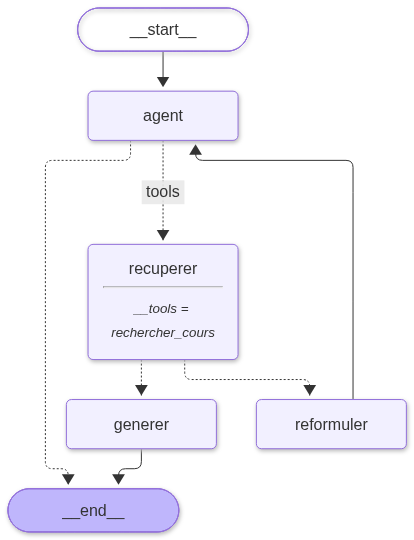

In [7]:
from langgraph.checkpoint.memory import InMemorySaver

workflow = StateGraph(EtatRAG)
workflow.add_node("agent", agent)
workflow.add_node("recuperer", ToolNode([rechercher_cours]))
workflow.add_node("reformuler", reformuler)
workflow.add_node("generer", generer)

workflow.add_edge(START, "agent")
workflow.add_conditional_edges("agent", tools_condition, {"tools": "recuperer", END: END})
workflow.add_conditional_edges("recuperer", evaluer_pertinence)
workflow.add_edge("reformuler", "agent")
workflow.add_edge("generer", END)

chatbot = workflow.compile(checkpointer=InMemorySaver())
afficher_graphe(chatbot)

## 5. Tests du chatbot

La fonction `discuter` suit l'exécution nœud par nœud (`stream_mode="updates"`) pour montrer les décisions de l'agent.

In [8]:
def discuter(question: str, thread_id: str = "conversation-1"):
    print(f"Vous : {question}")
    config = {"configurable": {"thread_id": thread_id}}
    reponse = ""
    for mise_a_jour in chatbot.stream({"messages": [HumanMessage(question)]}, config=config, stream_mode="updates"):
        for noeud, valeur in mise_a_jour.items():
            dernier = valeur["messages"][-1]
            if isinstance(dernier, AIMessage) and dernier.tool_calls:
                print(f"  [{noeud}] recherche : {[tc['args']['requete'] for tc in dernier.tool_calls]}")
            elif isinstance(dernier, ToolMessage):
                pages = [ligne.split("]")[0] + "]" for ligne in dernier.content.split("\n\n")]
                print(f"  [{noeud}] passages retrouvés : {pages}")
            elif isinstance(dernier, AIMessage):
                print(f"  [{noeud}] réponse rédigée")
                reponse = dernier.content
    display(Markdown(reponse))
    print("=" * 90)

In [9]:
# Salutation : l'agent répond sans chercher (agent -> END)
discuter("Bonjour ! Je révise le cours sur les agents.")

Vous : Bonjour ! Je révise le cours sur les agents.


  [agent] réponse rédigée


Bonjour ! N'hésite pas à me poser des questions si tu as besoin d'aide pour réviser le cours sur les agents. Que souhaites-tu revoir en particulier ?

In [10]:
# Question du cours : agent -> recuperer -> pertinent -> generer
discuter("Quelle est la différence entre LangChain et LangGraph selon le cours ?")

Vous : Quelle est la différence entre LangChain et LangGraph selon le cours ?


  [agent] recherche : ['LangChain LangGraph différence comparaison agents Agentic AI middlewares MCP']


  [evaluer_pertinence] oui : Les passages p. 42 et p. 43 comparent explicitement LangChain et LangGraph selon le cours, détaillant leurs différences en termes de fonctionnalités et cas d'usage.
  [recuperer] passages retrouvés : ['[p. 1]', '[p. 43]', '[p. 41]', '[p. 42]', '[p. 2]', '[p. 5]']


  [generer] réponse rédigée


La différence entre LangChain et LangGraph, selon le cours, peut être résumée ainsi :

1. **Nature et niveau d’abstraction**  
   - **LangChain** est un framework fournissant des **briques de base et des abstractions de haut niveau**. Il est conçu pour prototyper rapidement, chaîner des prompts, des outils et des retrievers, et construire des cas simples à moyens.  
   - **LangGraph** est un **framework d’orchestration d’agents complexes**, avec une abstraction de bas niveau sous forme de graphe. Il modélise le système comme un graphe d’états et de transitions, permettant des workflows multi-étapes non linéaires, avec des boucles, des branches conditionnelles, et des retours en arrière [p. 42, p. 43].

2. **Gestion de l’état et complexité des workflows**  
   - LangChain montre ses limites quand il s’agit de gérer des agents complexes avec un **état persistant**, des boucles, des branches, des retries, ou encore l’insertion d’un humain dans la boucle.  
   - LangGraph, en revanche, offre une **gestion d’état centralisée et structurée**, pensée pour des exécutions durables et reprenables (sauvegarde d’état, reprise après crash, checkpointing, human-in-the-loop) [p. 42, p. 43].

3. **Robustesse et production**  
   - LangGraph est préférable pour des systèmes où la **prévisibilité est importante** (workflows déterministes) et il est prêt pour un **déploiement en production** avec des outils de débogage comme LangSmith et LangGraph Studio.  
   - LangChain est plus adapté à des prototypes ou des cas simples, mais moins robuste pour des systèmes complexes en production [p. 42, p. 43].

En résumé, **LangChain est adapté pour des développements rapides et simples**, tandis que **LangGraph est conçu pour orchestrer des agents complexes avec des workflows avancés, une gestion d’état robuste et une exécution fiable en production**.

Références : [p. 42], [p. 43].

In [11]:
# Suite de la conversation (même thread) : la mémoire permet de comprendre « ce dernier »
discuter("Comment ce dernier gère-t-il la mémoire d'une conversation ?")

Vous : Comment ce dernier gère-t-il la mémoire d'une conversation ?


  [agent] recherche : ['LangGraph mémoire conversation gestion état persistant checkpointing reprise sauvegarde état human-in-the-loop']


  [evaluer_pertinence] oui : Le passage p.67 montre un exemple concret de gestion de mémoire d'une conversation avec InMemorySaver, illustrant comment l'état de la conversation est sauvegardé et utilisé pour répondre aux questions ultérieures.
  [recuperer] passages retrouvés : ['[p. 44]', '[p. 43]', '[p. 67]', '[p. 45]', '[p. 109]', '[p. 54]']


  [generer] réponse rédigée


Pour répondre à la question « Comment ce dernier gère-t-il la mémoire d'une conversation ? », en se basant uniquement sur les passages fournis, voici une réponse claire et structurée :

---

### Gestion de la mémoire d'une conversation dans LangGraph

1. **État centralisé et partagé**  
LangGraph utilise un **état (State)** centralisé qui capture l’instantané actuel de l’application, incluant les données de la conversation. Cet état est une structure de données partagée, souvent un dictionnaire ou un modèle, qui est mis à jour au fur et à mesure du traitement par les différents nœuds du graphe [p. 44].  
Cet état centralisé permet de stocker les messages échangés dans la conversation, ainsi que d’autres informations pertinentes, garantissant une mémoire cohérente et accessible à tous les agents ou nœuds impliqués.

2. **Mise à jour de l’état via les nœuds**  
Les nœuds sont des fonctions qui prennent l’état actuel en entrée, exécutent des actions (comme traiter un message ou générer une réponse), puis renvoient un état mis à jour [p. 45]. Cette architecture permet de gérer la mémoire conversationnelle de manière dynamique et modulaire, chaque nœud pouvant modifier ou enrichir l’état partagé.

3. **Exemple concret avec mémoire en mémoire vive (InMemorySaver)**  
Un exemple précis est donné à la page 67, où la mémoire de la conversation est gérée via un objet `InMemorySaver` qui sert de **checkpointer** (sauvegarde en mémoire vive).  
- Le workflow est compilé avec ce checkpointer : `graph_with_memory = workflow.compile(checkpointer=memory)`  
- Lorsqu’une première requête est envoyée avec un message humain ("Mon nom est Mohamed"), la réponse est générée et stockée.  
- Lors d’une requête suivante ("C'est quoi mon nom ?"), le système utilise la mémoire sauvegardée pour répondre correctement ("Votre nom est Mohamed.")  
- L’état courant de la conversation, incluant la liste des messages, peut être récupéré via `graph_with_memory.get_state(config).values['messages']`.  
Cela montre que la mémoire de la conversation est maintenue et accessible tout au long du dialogue, permettant une continuité et une cohérence dans les échanges [p. 67].

4. **Durabilité et reprise**  
LangGraph est conçu pour des exécutions durables et reprenables, avec la possibilité de sauvegarder l’état exact, de reprendre après un crash, ou d’insérer un humain dans la boucle [p. 43]. Cette capacité renforce la gestion de la mémoire conversationnelle en assurant que l’état de la conversation n’est pas perdu et peut être restauré.

---

### Conclusion

LangGraph gère la mémoire d’une conversation en centralisant toutes les données pertinentes dans un état partagé, qui est continuellement mis à jour par des nœuds fonctionnels. La mémoire peut être sauvegardée en mémoire vive via un système de checkpointing (`InMemorySaver`), permettant de conserver l’historique des messages et d’assurer la continuité du dialogue. Cette architecture garantit une gestion structurée, durable et accessible de la mémoire conversationnelle [p. 43-45, 67].

---

Si vous souhaitez plus de détails techniques ou d’autres exemples, les passages fournis ne suffisent pas à approfondir davantage.

In [12]:
# Question hors du cours : passages non pertinents -> reformulations -> limite -> réponse honnête
discuter("Que dit le cours sur l'entraînement des réseaux GAN ?", thread_id="conversation-2")

Vous : Que dit le cours sur l'entraînement des réseaux GAN ?


  [agent] recherche : ['entraînement réseaux GAN GAN training Generative Adversarial Networks apprentissage adversarial']


  [evaluer_pertinence] non : Les passages retrouvés ne contiennent aucune information sur l'entraînement des réseaux GAN.
  [recuperer] passages retrouvés : ['[p. 80]', '[p. 81]', '[p. 8]', '[p. 1]', '[p. 104]', '[p. 78]']


  [reformuler] nouvelle requête : « training of GANs in LangChain LangGraph AI agents MCP protocol course »


  [agent] recherche : ['training GANs LangChain LangGraph AI agents MCP protocol apprentissage réseaux antagonistes Generative Adversarial Networks']


  [evaluer_pertinence] non : Les passages parlent de LangChain, LangGraph, et agents AI, mais ne traitent pas directement de l'entraînement des GANs dans le contexte LangChain LangGraph AI agents MCP protocol course.
  [recuperer] passages retrouvés : ['[p. 1]', '[p. 41]', '[p. 43]', '[p. 42]', '[p. 80]', '[p. 81]']


  [reformuler] nouvelle requête : Training of GANs within LangChain and LangGraph AI agents using the MCP protocol – technical course materials and implementation guides


  [agent] recherche : ['training GANs LangChain LangGraph AI agents MCP protocol technical course implementation guide apprentissage réseaux antagonistes Generative Adversarial Networks']
  [evaluer_pertinence] limite de 2 reformulations atteinte -> generer
  [recuperer] passages retrouvés : ['[p. 1]', '[p. 41]', '[p. 80]', '[p. 81]', '[p. 43]', '[p. 42]']


  [generer] réponse rédigée


Le cours ne fournit aucune information sur l'entraînement des réseaux GAN (Generative Adversarial Networks). Les passages disponibles portent principalement sur des frameworks d’orchestration d’agents d’IA, notamment LangChain et LangGraph, ainsi que sur des exemples d’agents RAG (Retrieval-Augmented Generation) et leur configuration technique [p. 1, p. 41, p. 42, p. 43, p. 80, p. 81].

Plus précisément :

- Les pages 41, 42 et 43 comparent LangChain et LangGraph, en insistant sur leurs usages respectifs pour la gestion d’agents IA et de workflows complexes, mais sans mentionner les GAN.
- Les pages 80 et 81 montrent des exemples de configuration pour tester des agents RAG avec LangGraph Studio, sans aborder l’entraînement de réseaux de neurones ou de GAN.

En conclusion, **le cours ne traite pas de l’entraînement des réseaux GAN**. Si vous souhaitez des informations sur ce sujet, il faudra consulter d’autres ressources spécifiques aux GAN.

In [13]:
# Question sur le MCP
discuter("Quels sont les modes de transport d'un serveur MCP et lequel utiliser pour un serveur distant ?", thread_id="conversation-3")

Vous : Quels sont les modes de transport d'un serveur MCP et lequel utiliser pour un serveur distant ?


  [agent] recherche : ['modes de transport serveur MCP transport modes MCP server remote server serveur distant']


  [evaluer_pertinence] oui : Les passages décrivent les modes de transport standardisés par MCP (STDIO, SSE, Streamable HTTP) et mentionnent leur usage, ce qui permet de répondre à la question sur les modes de transport d'un serveur MCP et le choix pour un serveur distant.
  [recuperer] passages retrouvés : ['[p. 37]', '[p. 34]', '[p. 5]', '[p. 33]', '[p. 39]', '[p. 38]']


  [generer] réponse rédigée


Les modes de transport d’un serveur MCP sont décrits dans le passage de la page 34. Le protocole MCP définit deux mécanismes standards pour la communication client-serveur :

1. **STDIO** : communication via l’entrée standard (stdin) et la sortie standard (stdout).
2. **SSE (Server Sent Event)** : communication en streaming du serveur vers le client, avec des requêtes POST séparées du client vers le serveur.
3. **Streamable HTTP** : un échange HTTP full-duplex utilisant NDJSON, avec HTTP/1.1 chunked ou HTTP/2.

Ces modes permettent d’intégrer et de standardiser la communication dans l’écosystème des applications IA via MCP [p. 34].

Concernant le choix du mode de transport pour un serveur distant, le passage ne le précise pas explicitement. Cependant, on peut déduire que :

- **STDIO** est adapté pour une communication locale, car elle repose sur les flux standards d’un processus local.
- **SSE** et **Streamable HTTP** sont plus adaptés pour une communication réseau, donc pour un serveur distant, car ils utilisent des protocoles HTTP et des mécanismes de streaming adaptés aux échanges sur réseau.

Ainsi, pour un serveur MCP distant, il est préférable d’utiliser **SSE** ou **Streamable HTTP** comme mode de transport.

En résumé :

- Modes de transport MCP : STDIO, SSE, Streamable HTTP.
- Pour un serveur distant, utiliser SSE ou Streamable HTTP, car STDIO est local [p. 34].

Si vous souhaitez plus de détails sur la mise en œuvre ou les avantages spécifiques de chaque mode, les passages fournis ne contiennent pas cette information.

## 6. Test avec LangGraph Studio

LangGraph Studio est une interface web qui affiche le graphe, exécute des conversations et montre l'état à chaque nœud.

**Fichiers :**
- `rag_agentique/graphe.py` : le même graphe que ci-dessus, dans un module Python (variable `graph`)
- `langgraph.json` (racine de l'AP5) : déclare le graphe et le fichier `.env`

```json
{
  "dependencies": ["."],
  "graphs": { "rag_agentique": "./rag_agentique/graphe.py:graph" },
  "env": ".env"
}
```

**Lancement** (terminal, dossier de l'AP5) :
```bash
uv run langgraph dev
```
Studio s'ouvre sur `https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024` (connexion gratuite à LangSmith).

La cellule suivante démarre le même serveur `langgraph dev` en arrière-plan et l'interroge avec le SDK, exactement comme le fait Studio.

In [14]:
import subprocess
import time

import httpx

log_serveur = open("langgraph_dev.log", "w", encoding="utf-8")
serveur_studio = subprocess.Popen(
    [str(Path(sys.executable).parent / "langgraph"), "dev", "--no-browser", "--no-reload", "--port", "2024"],
    stdout=log_serveur, stderr=subprocess.STDOUT, env={**os.environ, "PYTHONIOENCODING": "utf-8"},
)
for _ in range(60):
    try:
        if httpx.get("http://127.0.0.1:2024/ok", timeout=2).status_code == 200:
            break
    except httpx.HTTPError:
        time.sleep(2)
print("Serveur LangGraph démarré :", httpx.get("http://127.0.0.1:2024/ok").json())
print("Studio : https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024")

Serveur LangGraph démarré : {'ok': True, 'services': {}}
Studio : https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024


In [15]:
from langgraph_sdk import get_client

client = get_client(url="http://127.0.0.1:2024")
print("Graphes disponibles :", [a["graph_id"] for a in await client.assistants.search()])

thread = await client.threads.create()
async for evenement in client.runs.stream(thread["thread_id"], "rag_agentique", stream_mode="updates",
                                         input={"messages": [{"role": "user", "content": "À quoi sert le Human in the loop ?"}]}):
    if evenement.event == "updates":
        for noeud, valeur in evenement.data.items():
            print(f"[{noeud}]")
etat = await client.threads.get_state(thread["thread_id"])
display(Markdown(etat["values"]["messages"][-1]["content"]))

Graphes disponibles : ['rag_agentique']


[agent]


[recuperer]


[generer]


Le **Human in the loop** (HITL) désigne une intervention humaine intégrée dans un processus automatisé, notamment dans le cadre de l’utilisation de modèles de langage (LLM). Son rôle principal est de permettre une validation ou une approbation humaine avant l’exécution d’actions sensibles ou à fort enjeu.

D’après les passages du cours, le Human in the loop sert à :

1. **Assurer une validation humaine avant des opérations critiques** : Par exemple, avant d’envoyer un email, de réaliser une transaction financière, ou de modifier des données en production, une personne doit approuver l’action. Cela évite des erreurs ou des conséquences non désirées liées à une automatisation complète sans contrôle [p. 26].

2. **Agir comme un garde-fou efficace** : Le middleware Human-in-the-loop, comme celui fourni par LangChain, est un mécanisme intégré qui exige cette approbation humaine, ce qui est particulièrement important pour les décisions à forts enjeux [p. 26].

3. **Permettre un retour d’information** : Le système conserve un état avec des éléments comme le destinataire, le sujet, l’intention, le brouillon, l’approbation et le feedback, ce qui montre que l’humain peut non seulement valider mais aussi fournir un retour sur la proposition générée par le modèle [p. 98, p. 96, p. 97].

En résumé, le Human in the loop sert à intégrer une étape de contrôle humain dans des processus automatisés pour garantir la sécurité, la fiabilité et la pertinence des actions effectuées par des systèmes automatisés, notamment dans des contextes sensibles ou à fort impact [p. 26, p. 98].

---

**Références** :  
- p. 26 (Guardrails : Human-in-the-loop)  
- p. 96, 97, 98 (état et validation dans Human In The Loop)

In [16]:
# Arrêt du serveur et de ses processus enfants (dont celui qui écoute sur le port 2024)
import psutil

processus = psutil.Process(serveur_studio.pid)
for p in processus.children(recursive=True) + [processus]:
    p.kill()
for connexion in psutil.net_connections(kind="tcp"):
    if connexion.laddr.port == 2024 and connexion.status == "LISTEN" and connexion.pid:
        psutil.Process(connexion.pid).kill()
log_serveur.close()
print("Serveur arrêté")

Serveur arrêté


## 7. Interface web Streamlit

Fichier : `rag_agentique/app_streamlit.py`
- historique de la conversation (`st.chat_message`, `st.chat_input`) et `thread_id` par session pour la mémoire
- graphe chargé une seule fois (`st.cache_resource`)
- panneau « Étapes de l'agent » : recherches lancées, pages retrouvées, reformulations

**Lancement** (terminal, dossier de l'AP5) :
```bash
uv run streamlit run rag_agentique/app_streamlit.py
```
L'application s'ouvre sur `http://localhost:8501`.

La cellule suivante teste l'application sans navigateur avec `streamlit.testing` (`AppTest`) : elle saisit deux questions et lit les réponses affichées.

In [17]:
from streamlit.testing.v1 import AppTest

# Chemin absolu : AppTest résout les chemins relatifs par rapport au fichier appelant, pas au dossier courant
app = AppTest.from_file(str(Path("rag_agentique/app_streamlit.py").resolve()), default_timeout=180)
app.run()
print("Titre :", app.title[0].value)

for question in ["Qu'est-ce que le pattern ReAct ?", "Donne un exemple de tool vu dans ce cours."]:
    app.chat_input[0].set_value(question).run()
    reponse = app.chat_message[-1].markdown[0].value
    print(f"\nVous : {question}\nAssistant : {reponse[:500]}")

2026-11-26 11:12:45.476 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Titre : 🤖 Chatbot Agentic RAG



Vous : Qu'est-ce que le pattern ReAct ?
Assistant : Le pattern **ReAct** (Reasoning and Action) est un design pattern utilisé dans le fonctionnement des agents d'intelligence artificielle (AI Agents). Voici une explication claire et structurée basée sur les passages fournis :

### Définition du pattern ReAct
Le pattern ReAct décrit un cycle en plusieurs étapes que suit un agent AI pour interagir efficacement avec son environnement :

1. **Raisonnement (Reasoning)** : Le cerveau de l’agent, généralement un modèle de langage (LLM), analyse la situa



Vous : Donne un exemple de tool vu dans ce cours.
Assistant : Un exemple de tool (outil) vu dans ce cours est le **retriever_tool** utilisé dans l’Agentic RAG. Ce tool permet de récupérer des informations spécifiques à partir d’une requête, comme dans l’exemple où la requête porte sur le sujet de la thèse, l’auteur, et la liste des membres du jury et directeurs de la thèse. Le log montre que l’agent décide d’utiliser ce tool pour traiter la demande, puis exécute une requête HTTP vers une API d’embeddings pour obtenir les résultats [p. 78].

Par ailleurs, l


In [18]:
# Le panneau « Étapes de l'agent » de la dernière réponse
print(app.chat_message[-1].expander[-1].markdown[0].value)

- **agent** : recherche dans le cours « tool example tool usage tool in Agentic AI LangChain LangGraph MCP R4 R5 R6 A2A »
- **recuperer** : passages des pages 1, 2, 39, 41, 78, 80
- **generer** : réponse rédigée


**Bilan :** le graphe Agentic RAG ajoute au RAG classique la **décision** (chercher ou non), le **contrôle qualité** des passages et la **reformulation**. Le même graphe est exécuté dans le notebook, servi par `langgraph dev` pour LangGraph Studio, et utilisé par l'interface Streamlit.